# Reproduce Fig.1a's numbers & Table 6's Significance tests
we show how to reproduce each number in the dumbbell plot in Fig1(a) (see correlation matrices visualization for each method)


Set up all configurations

In [1]:
# Experiment CONFIG
N_REPEAT = 5  # NOTE total runs = 2*N_REPEAT, due to test/train splits for each repeat
N_GROUPS = 4

## GEM CONFIG
GH_NODES = 200
MAX_ITER = 200
RIDGE_LAMBDA = 0.1
RIDGE_GAMMA = 0.1
RIDGE_A = 0.5
MU_GAMMA = 0.01
RIDGE_B = 0.1

RIDGE_KAPPA= 0.1
MU_KAPPA= -0.01
KAPPA_MAX =-0.00001
RIDGE_X0 = 1000
OPTIMAL_KAPPA_INIT = True

KENDALL_TAU = True

## Data CONFIG
strict_Y_int = False
MATH_ONLY = False # 1st priority config
INCLUDE_MATH = True # 2nd priority config

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

# Graphical configs
# 1. Reset seaborn to baseline
sns.set_style('whitegrid')
sns.set_context('paper') # Remove font_scale!

# 2. Hardcode the absolute font sizes for publication
plt.rcParams.update({
    'font.size': 9,             # Global baseline
    'figure.titlesize': 9,      # Global figure titles (Added)
    'axes.titlesize': 10,       # Title of the subplot (ax.set_title)
    'axes.labelsize': 9,        # X and Y axis labels
    'xtick.labelsize': 8,       # Numbers on the X axis
    'ytick.labelsize': 8,       # Numbers on the Y axis
    'legend.fontsize': 8,       # Legend text
    'legend.title_fontsize': 8  # Legend title
})

### Data loading

In [3]:
B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [4]:
B = pd.concat([B_language, B_coding, B_reasoning, B_math],axis=0)
Y = pd.concat([Y_language, Y_coding, Y_reasoning, Y_math],axis=0)
c = pd.concat([c_language, c_coding, c_reasoning, c_math],axis=0)

In [5]:
from reasoning_aware_irt.livebench_utils import reindex
_ = reindex(Y, B, c) # little helper to make sure that all dataframes have exactly the same sorted question_id indices

the model_id Y/B sequence is great!!
the question_id Y/B sequence is great!!
the question_id Y/c sequence is great!!


In [6]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:5])

(786, 42) (786, 42)
0.39359059581389527 1310.9940930570701
(786,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02]


In [7]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])
N_MODELS = len(model_list)

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


In [8]:
ID1=0
ID2=len(B_language)
ID3=len(B_language)+len(B_coding)
ID4=len(B_language)+len(B_coding)+len(B_reasoning)

## Repeat StratifiedShuffleSplit

In [9]:
labels = np.zeros_like(c_i) # for Stratification
print(labels.shape)
labels[:ID2] = 0
labels[ID2:ID3] = 1
labels[ID3:ID4] = 2
labels[ID4:] = 3

n_samples = len(labels)

(786,)


In [10]:
# Split Y into N_Groups according to rank
Y_avg = Y_ij.mean(axis=0)
sorted_model_idx = np.argsort(Y_avg)
print('sorted model_idx from worst to best:', sorted_model_idx)

N_MEMBERS_PER_GROUP = np.ceil(N_MODELS / N_GROUPS).astype(int)
print(f'number per group is :{N_MEMBERS_PER_GROUP}')
group_id_list = []

start_idx = 0
for n in range(N_GROUPS):
    group_id_list.append(sorted_model_idx[start_idx : start_idx+N_MEMBERS_PER_GROUP])
    start_idx += N_MEMBERS_PER_GROUP

# print(group_id_list)
print('last group (best):', model_list[group_id_list[-1]] )
print('avg score for last group:', Y_avg[group_id_list[-1]])

sorted model_idx from worst to best: [ 5  4  9  7 33 14 23  2 32 24  3  6 11 15  8 18 13 22 19 26 30  1 31 25
 16 12 17  0 20 27 40 38 41 28 21 29 37 10 34 36 39 35]
number per group is :11
last group (best): ['gpt-4o-2024-05-13' 'gemini-1.5-pro-exp-0827' 'gpt-4o-2024-08-06'
 'baidu/ernie-4.5-21b-a3b-thinking' 'claude-3-5-sonnet-20240620'
 'xiaomi/mimo-v2-flash:free' 'openai/gpt-oss-20b'
 'qwen/qwen3-30b-a3b-thinking-2507' 'openai/gpt-oss-120b']
avg score for last group: [0.50246943 0.52964697 0.53021659 0.54365762 0.56780583 0.68436126
 0.68598629 0.72200245 0.73651472]


In [11]:
from sklearn.model_selection import StratifiedShuffleSplit

ksplits_index_list = [] # for GEM below

scores_list = {} # actually dict of list! <-- store raw_accuracy for each group
scores_list["all"] = []
for k in range(N_GROUPS):
    scores_list[f"group_{k}"] = []

for n in range(N_REPEAT):
    sss = StratifiedShuffleSplit(n_splits=2, test_size=0.5, random_state=n)

    # first argument of split is not needed: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedShuffleSplit.html
    # temp_labels = np.array([0,0,0,0, 1, 1, 1,1,2, 2,2,2]) # just to test
    # for i, (train_index, test_index) in enumerate(sss.split(np.zeros(len(temp_labels)), temp_labels)):
        # print(train_index, test_index)
    
    print(f'round {n+1}:')
    for i, (train_index, test_index) in enumerate(sss.split(np.zeros(n_samples), labels)):

        ksplits_index_list.append(train_index)
        ksplits_index_list.append(test_index)
        
        Y_1 = Y_ij[train_index,:]
        Y_2 = Y_ij[test_index,:]

        scores_1 = Y_1.mean(axis=0)
        scores_2 = Y_2.mean(axis=0)
        
        scores_list["all"] += [scores_1, scores_2]
        for k in range(N_GROUPS):
            scores_list[f"group_{k}"] += [scores_1[group_id_list[k]], scores_2[group_id_list[k]]]
        
        break # need only first split per repeat, since above we append both train & test already

round 1:
round 2:
round 3:
round 4:
round 5:


In [12]:
from scipy.stats import spearmanr, kendalltau
if KENDALL_TAU:
    print('use Kendall tau')
    rank_stat_function = kendalltau
else:
    print('use Spearman rho')
    rank_stat_function = spearmanr

use Kendall tau


### correlation N_GROUPS matrices for raw_accuracy
Reproducing the number used in Fig1(a) for raw accuracy method

In [13]:
correlation_matrices_dict = {}

for k in range(N_GROUPS):
    
    correlation_matrices_dict[f"group_{k}"] = np.zeros((N_REPEAT*2, N_REPEAT*2)) # 2-splits per sss round
    
    for i in range(N_REPEAT*2):
        for j in range(N_REPEAT*2): # pairwise correlation per repeat 
            corr, _ = rank_stat_function( scores_list[f"group_{k}"][i] , scores_list[f"group_{k}"][j] )
            correlation_matrices_dict[f"group_{k}"][i, j] = corr

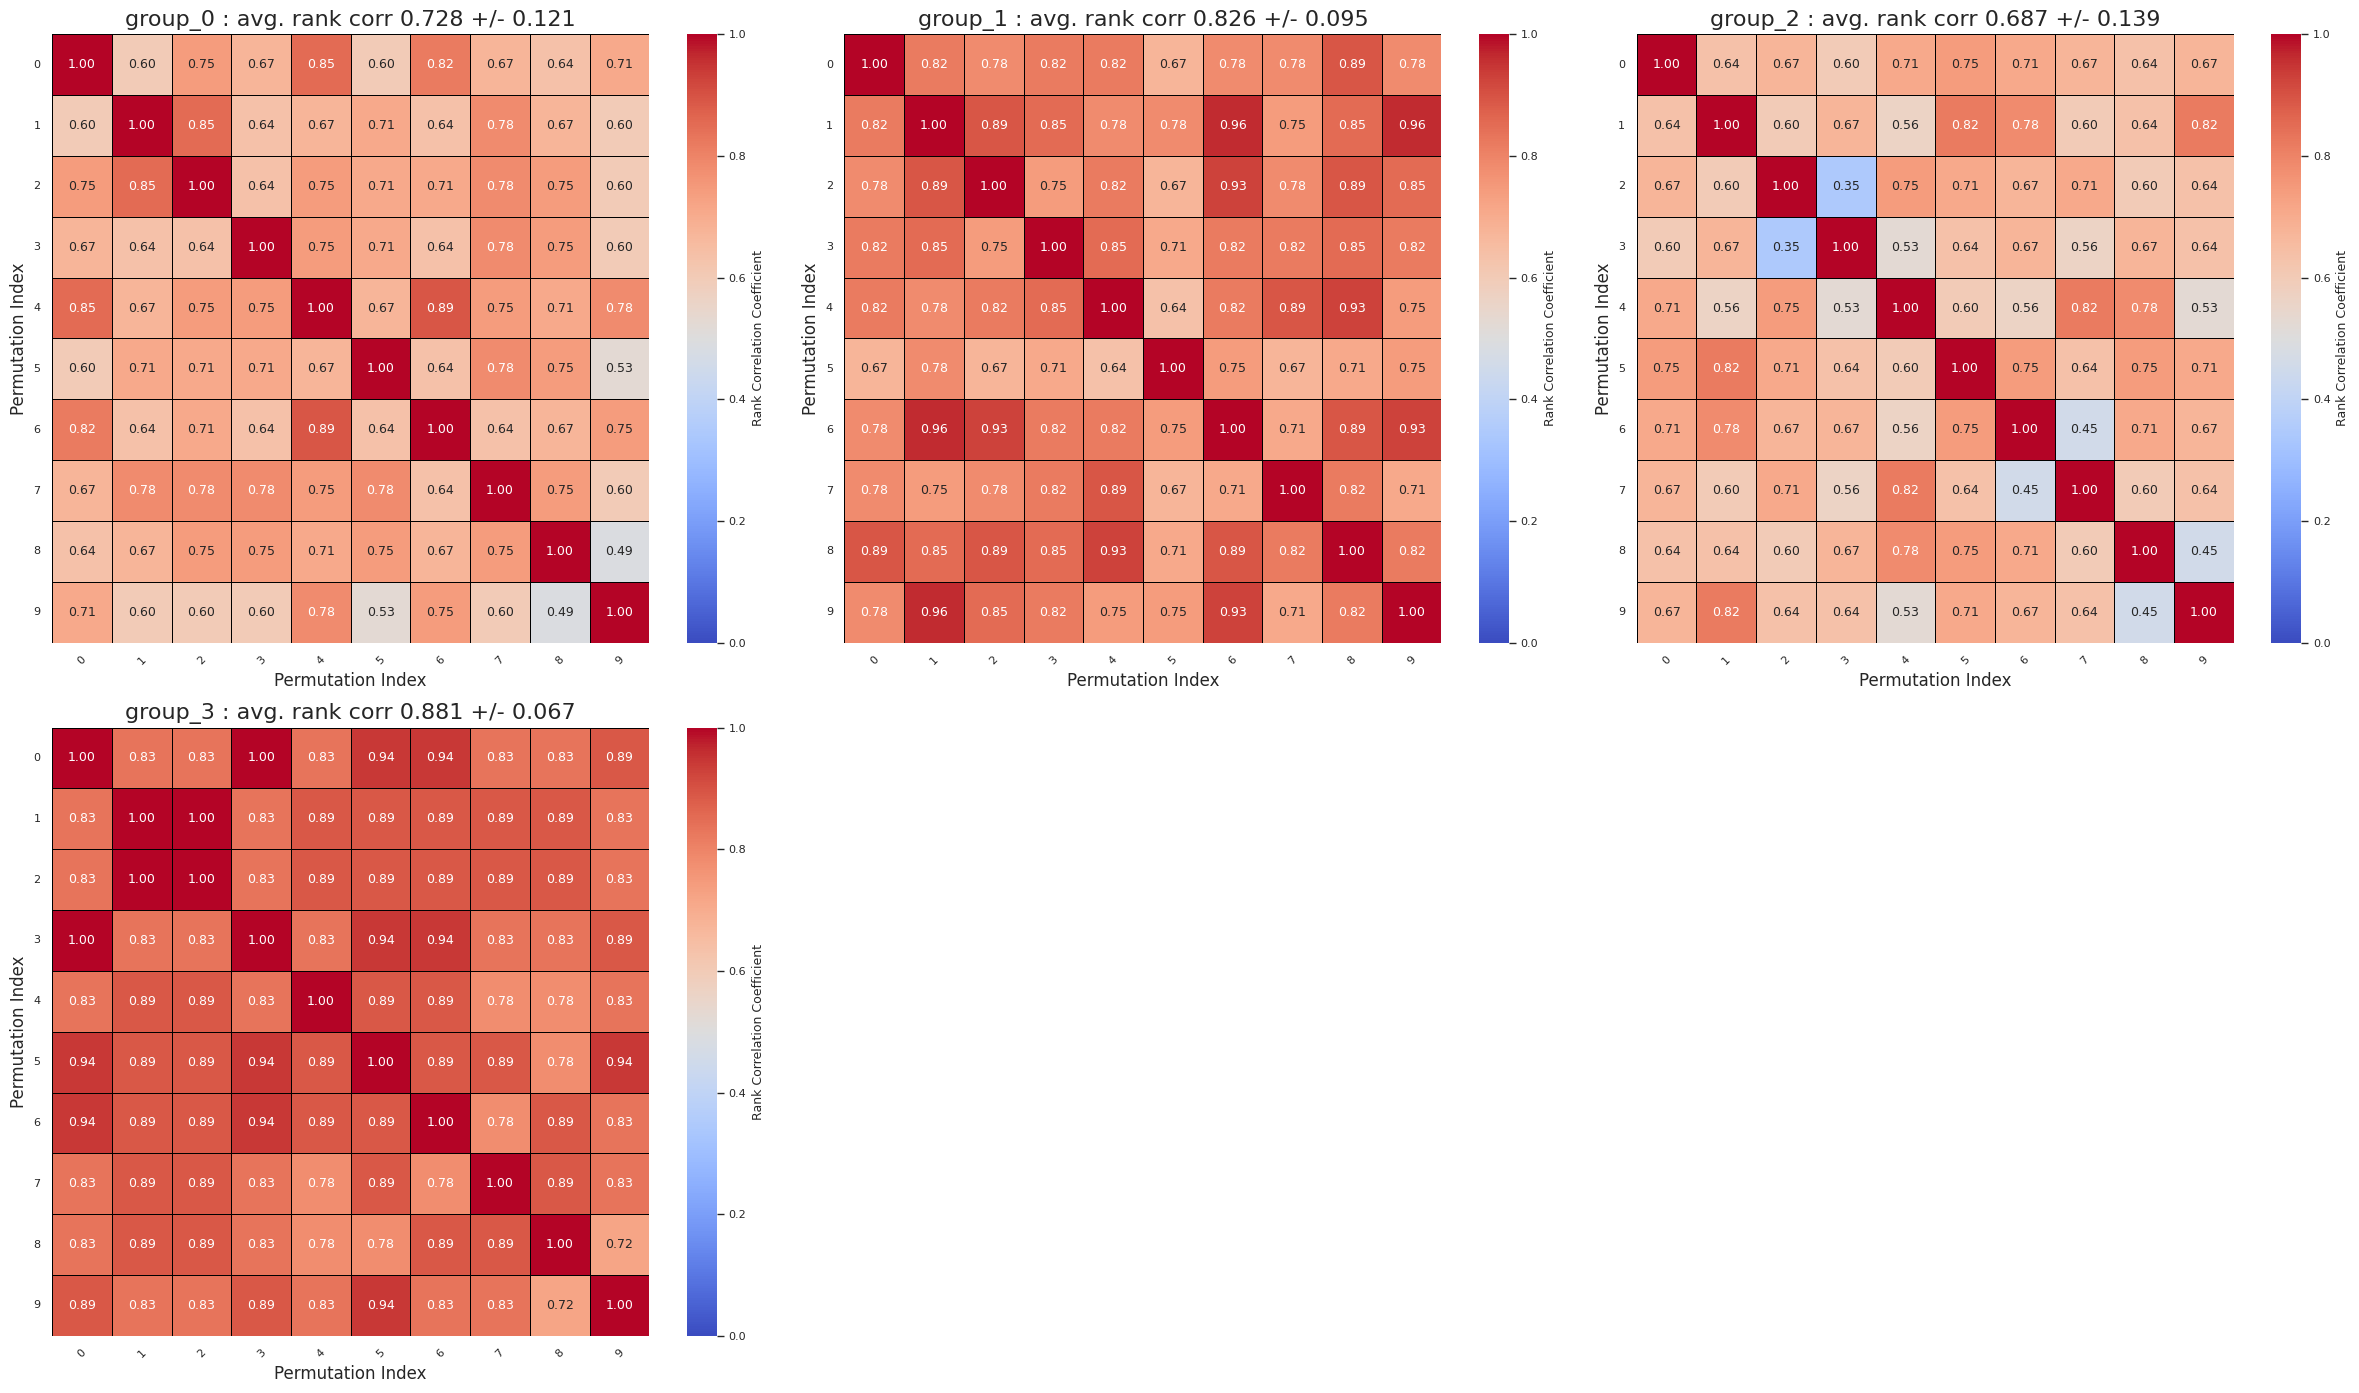

In [16]:
from reasoning_aware_irt.utils import plot_correlation_matrices_dynamic

title_list = [f"group_{k} : avg. rank corr {correlation_matrices_dict[f'group_{k}'].mean():.3f} +/- {correlation_matrices_dict[f'group_{k}'].std():.3f}" for k in range(N_GROUPS)]
matrix_list = [correlation_matrices_dict[f"group_{k}"]  for k in range(N_GROUPS)]
plot_correlation_matrices_dynamic(matrix_list, title_list)

### Next, GEM for Reasoning-Aware 3PL on the same split / groups
(to save notebook output space, we will clear the GEM log-output)

In [17]:
from reasoning_aware_irt.gem_quad import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem_quad import ReasoningAware3PLQuadraticCalibrator as ReasoningAware3PLCalibrator

In [18]:
gem_list = {}
gem_list["all_results"] = []
for k in range(N_GROUPS):
    gem_list[f"group_{k}_avg_budget"] = []
    gem_list[f"group_{k}_optimal_budget"] = []
for n, split_index in enumerate(ksplits_index_list):    
    print(f'\n ***** split_index {n+1} : {MAX_ITER}-iterations ****** \n')
          
    Y_split = Y_ij[split_index,:]
    B_split = B_ij[split_index,:]
    c_split = c_i[split_index]

    x0_j = np.log1p(B_split.mean(axis=0)) # budget regularizer (Eq.12 in the paper)

    data = CalibrationData(Y_ij=Y_split, B_ij=B_split, c_i=c_split)
    cfg = CalibrationConfig(
        gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
        ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA,
        ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
        mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
        ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT
        )
    calibrator = ReasoningAware3PLCalibrator(cfg)
    fit_results = calibrator.fit(data, strict_Y_int=strict_Y_int)

    gem_list["all_results"].append(fit_results)
    

    for k in range(N_GROUPS):
        avg_x = np.log1p(B_split[:, group_id_list[k]].mean(axis=0)) 
        theta_split = fit_results.theta_j_mean[group_id_list[k]] + fit_results.gamma_j[group_id_list[k]]*avg_x + fit_results.kappa_j[group_id_list[k]]*avg_x**2
        gem_list[f"group_{k}_avg_budget"].append(theta_split)        

iter  27  ll=-6928.096375   dLL=2.768e-02
iter  28  ll=-6928.034851   dLL=6.152e-02
iter  29  ll=-6928.011664   dLL=2.319e-02
iter  30  ll=-6927.887154   dLL=1.245e-01
iter  31  ll=-6927.736244   dLL=1.509e-01
iter  32  ll=-6927.561012   dLL=1.752e-01
iter  33  ll=-6927.321457   dLL=2.396e-01
iter  34  ll=-6927.109058   dLL=2.124e-01
iter  35  ll=-6926.971896   dLL=1.372e-01
iter  36  ll=-6926.827110   dLL=1.448e-01
iter  37  ll=-6926.723432   dLL=1.037e-01
iter  38  ll=-6926.660030   dLL=6.340e-02
iter  39  ll=-6926.521270   dLL=1.388e-01
iter  40  ll=-6926.412722   dLL=1.085e-01
iter  41  ll=-6926.316958   dLL=9.576e-02
iter  42  ll=-6926.218553   dLL=9.841e-02
iter  43  ll=-6926.113396   dLL=1.052e-01
iter  44  ll=-6926.009039   dLL=1.044e-01
iter  45  ll=-6925.889020   dLL=1.200e-01
iter  46  ll=-6925.775599   dLL=1.134e-01
iter  47  ll=-6925.700088   dLL=7.551e-02
iter  48  ll=-6925.644766   dLL=5.532e-02
iter  49  ll=-6925.569156   dLL=7.561e-02
iter  50  ll=-6925.490577   dLL=7.

In [22]:
theta_correlation_matrices_dict = {}

for k in range(N_GROUPS):
    
    theta_correlation_matrices_dict[f"group_{k}"] = np.zeros((N_REPEAT*2, N_REPEAT*2)) # 2-splits per sss round
    
    for i in range(N_REPEAT*2):
        for j in range(N_REPEAT*2): # pairwise correlation per repeat 
            corr, _ = rank_stat_function( gem_list[f"group_{k}_avg_budget"][i] , gem_list[f"group_{k}_avg_budget"][j] )
            theta_correlation_matrices_dict[f"group_{k}"][i, j] = corr

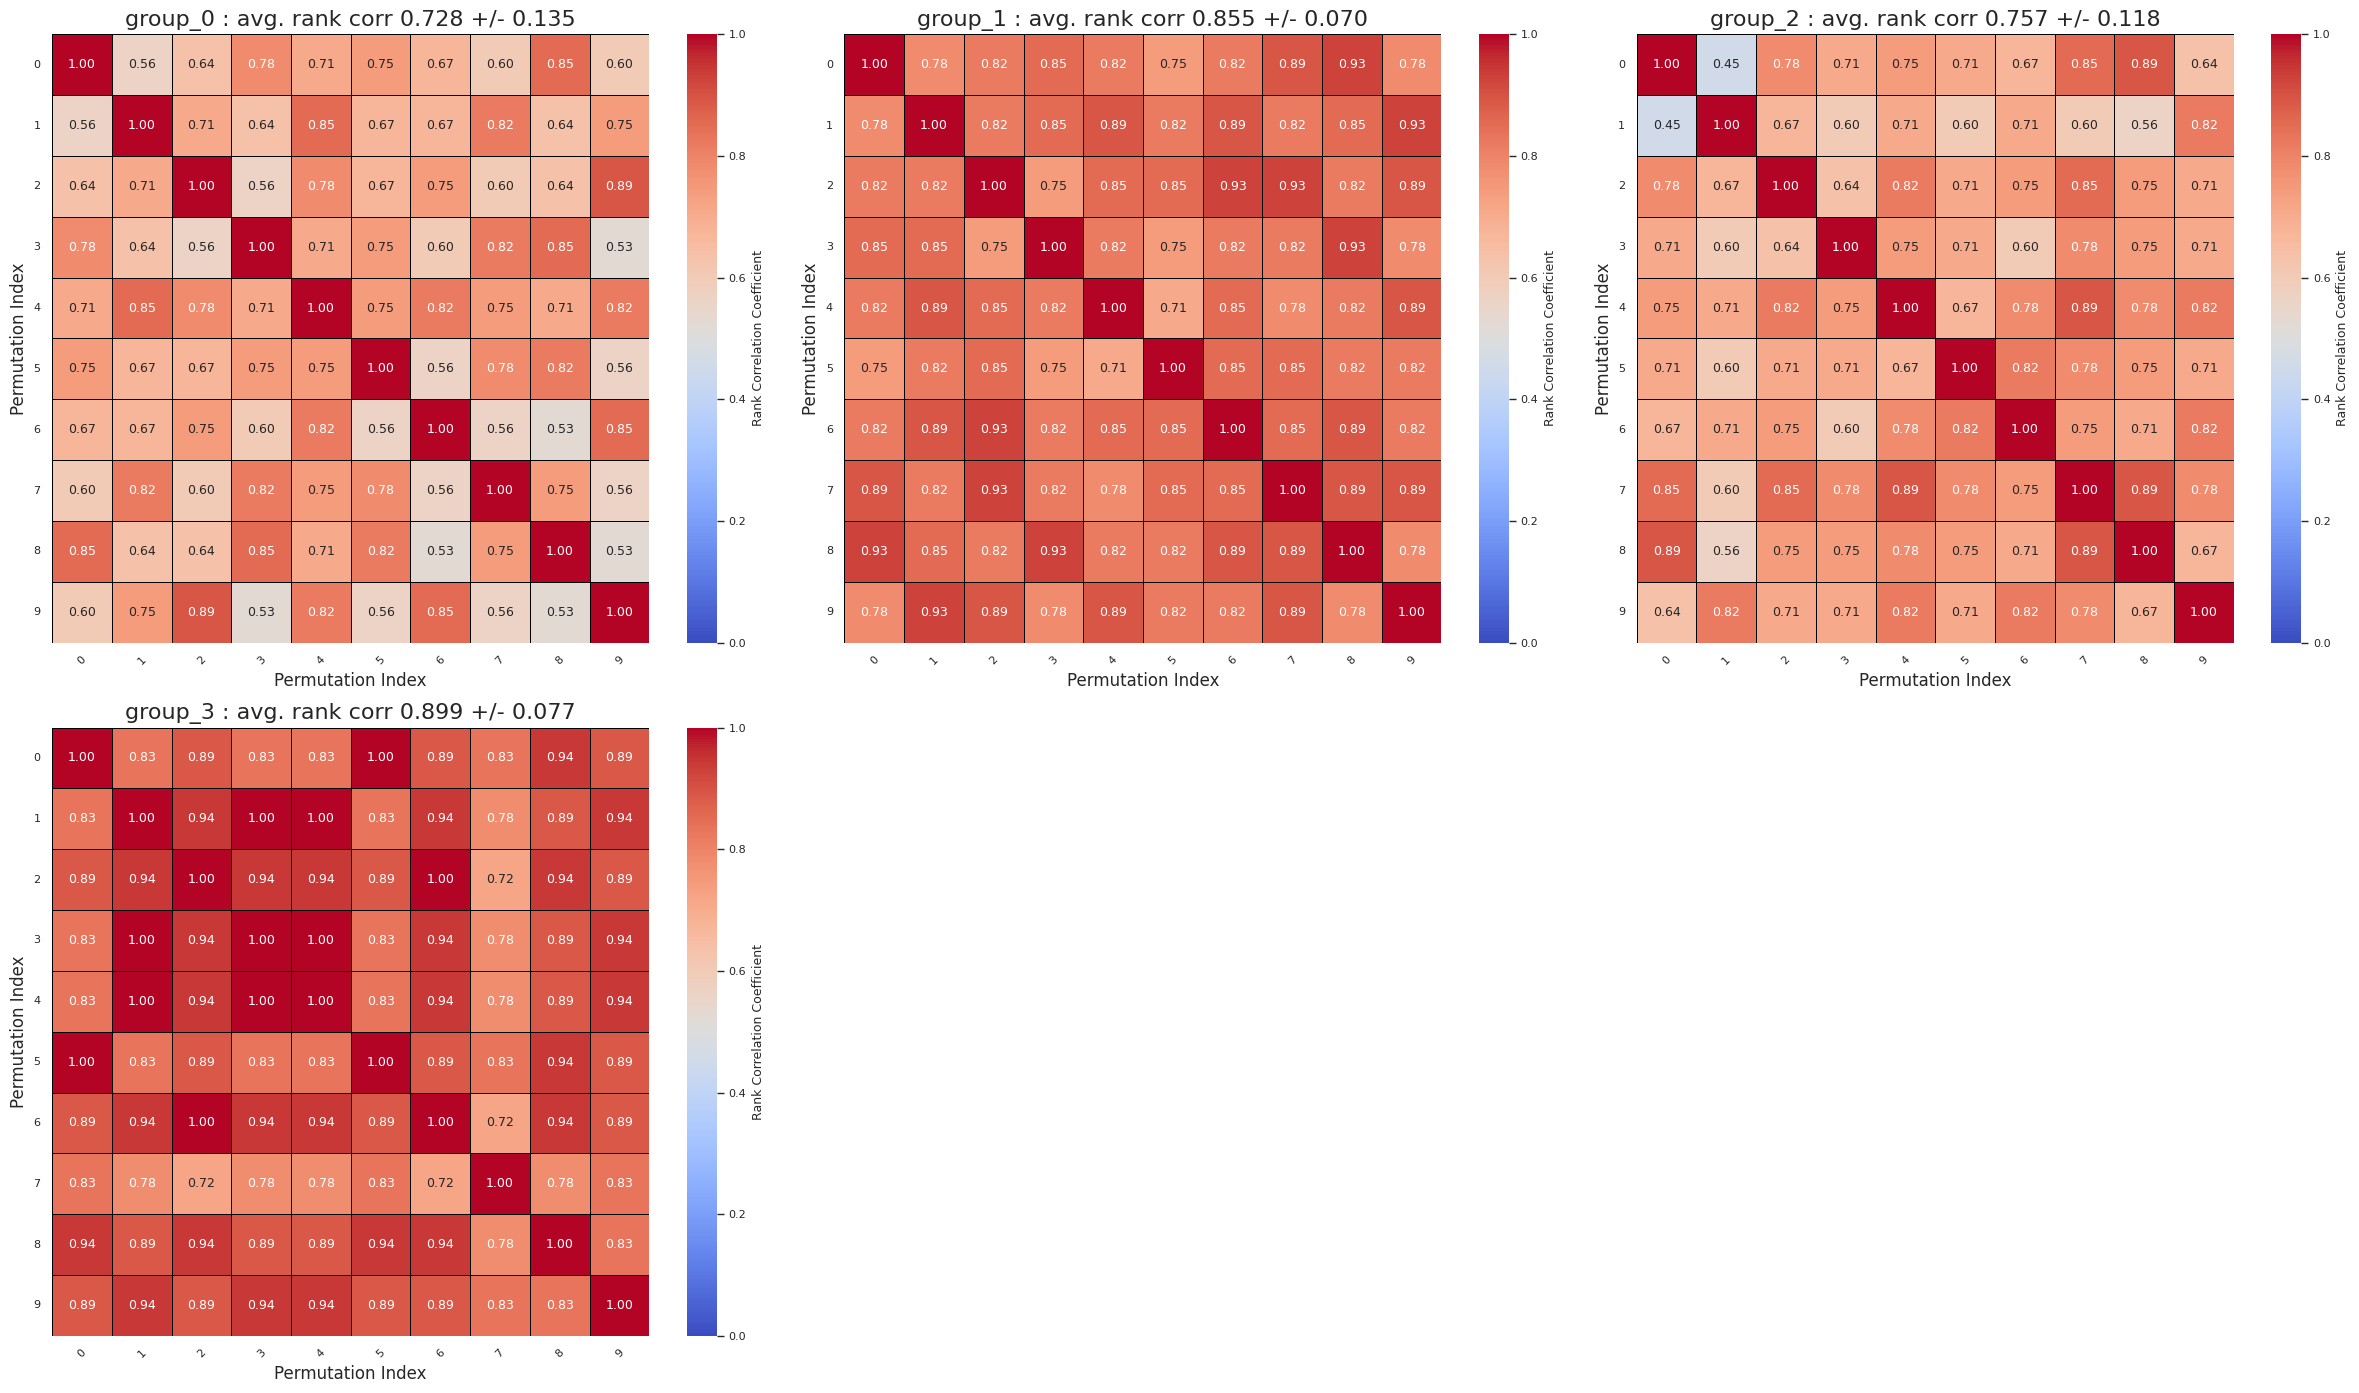

In [23]:
title_list = [f"group_{k} : avg. rank corr {theta_correlation_matrices_dict[f'group_{k}'].mean():.3f} +/- {theta_correlation_matrices_dict[f'group_{k}'].std():.3f}" for k in range(N_GROUPS)]
matrix_list = [theta_correlation_matrices_dict[f"group_{k}"]  for k in range(N_GROUPS)]
plot_correlation_matrices_dynamic(matrix_list, title_list)

## Next, Classic 3PL, fitting on the same splits & groups
(again, clear EM-fitting outputs to reduce space)

In [30]:
from reasoning_aware_irt.classic_irt_em import IRT3PLCalibrator
from reasoning_aware_irt.classic_irt_em import ClassicCalibrationData, ClassicCalibrationConfig

In [31]:
classic_list = {}
classic_list["all_results"] = []
for k in range(N_GROUPS):
    classic_list[f"group_{k}"] = []
for n, split_index in enumerate(ksplits_index_list):    
    print(f'\n ***** split_index {n+1} : {MAX_ITER}-iterations ****** \n')
          
    Y_split = Y_ij[split_index,:]
    c_split = c_i[split_index]

    data = ClassicCalibrationData(Y_ij=Y_split, c_i=c_split)
    cfg = ClassicCalibrationConfig(
        gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
        ridge_a=RIDGE_A, ridge_b=RIDGE_B 
        )
    calibrator = IRT3PLCalibrator(cfg)
    fit_results = calibrator.fit(data)

    classic_list["all_results"].append(fit_results)
    
    for k in range(N_GROUPS):
        theta_split = fit_results.theta_j_mean[group_id_list[k]] 
        classic_list[f"group_{k}"].append(theta_split)
        

iter=156  LL=-7054.825921  dLL=1.397e-04
iter=157  LL=-7054.825796  dLL=1.250e-04
iter=158  LL=-7054.825656  dLL=1.405e-04
iter=159  LL=-7054.825528  dLL=1.279e-04
iter=160  LL=-7054.825405  dLL=1.226e-04
iter=161  LL=-7054.825285  dLL=1.203e-04
iter=162  LL=-7054.825173  dLL=1.116e-04
iter=163  LL=-7054.825066  dLL=1.077e-04
iter=164  LL=-7054.824959  dLL=1.071e-04
iter=165  LL=-7054.824860  dLL=9.907e-05
converged at iter 165


In [32]:
classic_correlation_matrices_dict = {}

for k in range(N_GROUPS):
    
    classic_correlation_matrices_dict[f"group_{k}"] = np.zeros((N_REPEAT*2, N_REPEAT*2)) # 2-splits per sss round
    
    for i in range(N_REPEAT*2):
        for j in range(N_REPEAT*2): # pairwise correlation per repeat 
            corr, _ = rank_stat_function( classic_list[f"group_{k}"][i] , classic_list[f"group_{k}"][j] )
            classic_correlation_matrices_dict[f"group_{k}"][i, j] = corr



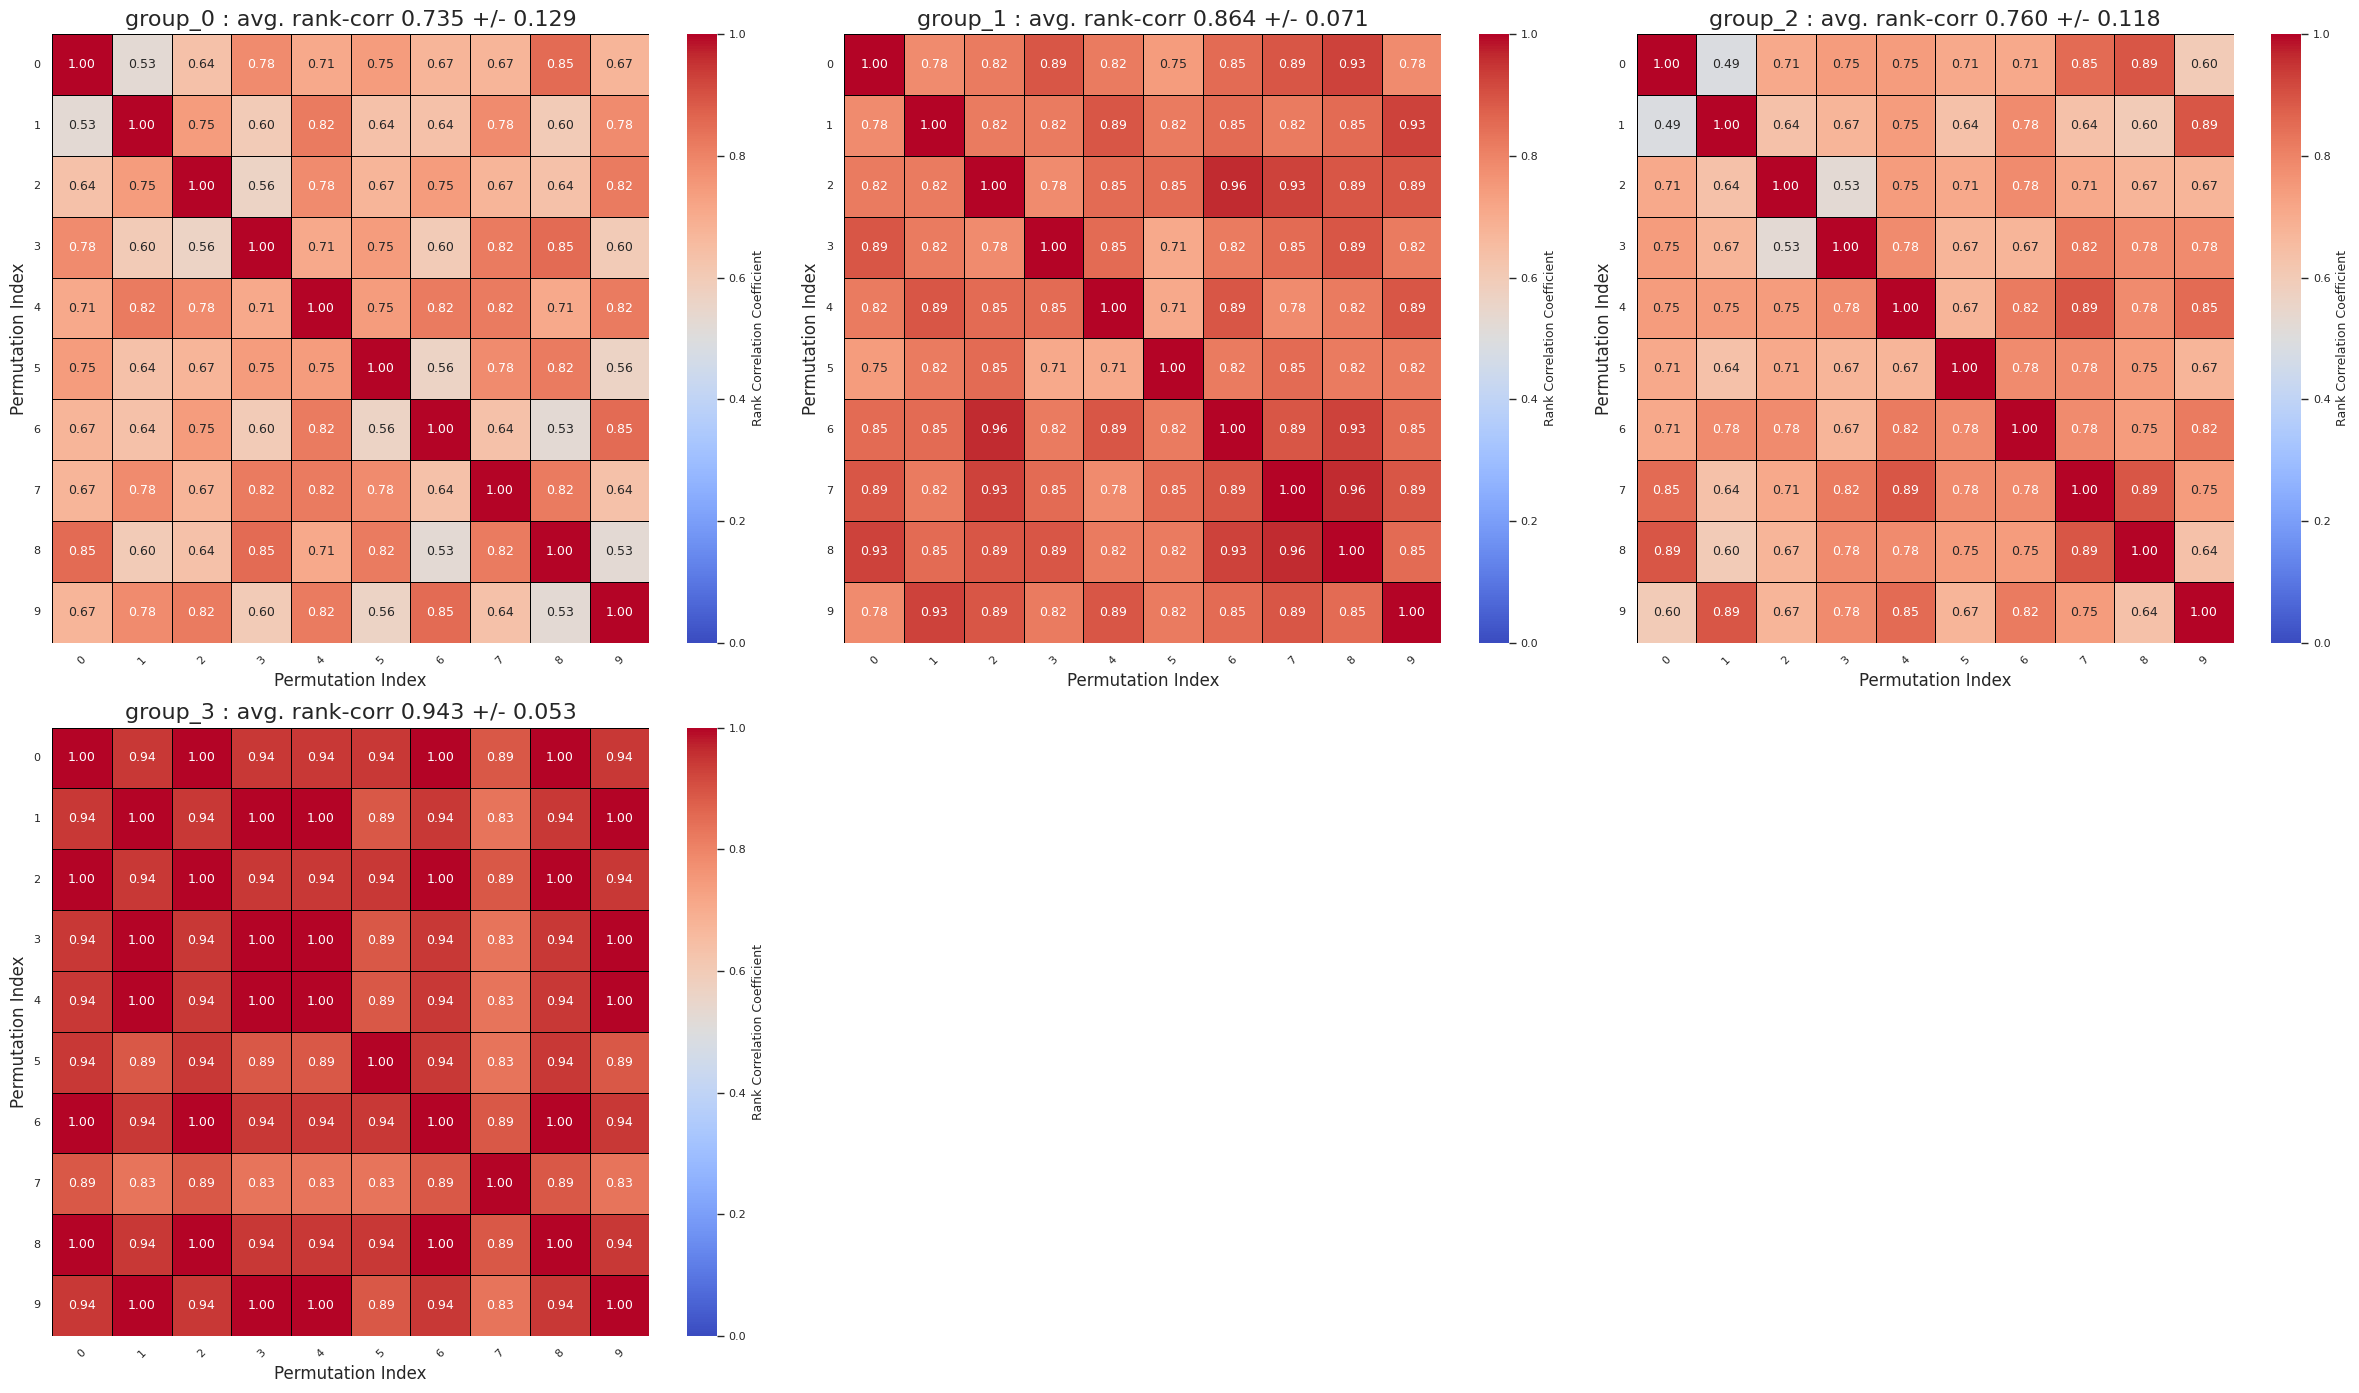

In [33]:
title_list = [f"group_{k} : avg. rank-corr {np.abs(classic_correlation_matrices_dict[f'group_{k}'].mean()):.3f} +/- {classic_correlation_matrices_dict[f'group_{k}'].std():.3f}" for k in range(N_GROUPS)]
matrix_list = [classic_correlation_matrices_dict[f"group_{k}"]  for k in range(N_GROUPS)]
plot_correlation_matrices_dynamic(matrix_list, title_list)

## Statistical Tests (Table 6)

In [24]:
def print_summary(p_val, val1, val2, test_name='paired-t', alternative='greater', alpha=0.05):
    win_rate = np.mean(val1 > val2) * 100
    
    print(f"--- Model Comparison Report ---")
    print(f"Test Used   : {test_name} (alternative='{alternative}')")
    print(f"Model 1 Mean  : {val1.mean():.4f}")
    print(f"Model 2 Mean  : {val2.mean():.4f}")
    print(f"Model 1 Win Rate  : {win_rate:.1f}% of individual predictions\n")
    
    print(f"Test Statistic : {stat:.4f}")
    print(f"p-value        : {p_val:.4e}\n")
    
    # 4. Formulate the explicit statistical conclusion
    if p_val < alpha:
        claim = "Model 1 is significantly BETTER than Model 2."
        reason = "its val is significantly better" if test_name == 'paired-t' else "it wins significantly more often"
            
        print(f"✅ CONCLUSION: {claim}")
        print(f"   At alpha={alpha}, we reject the null hypothesis because {reason}.")
    elif p_val < 0.1:
        print('It is significant at weaker alpha=0.1')
    else:
        print(f"❌ CONCLUSION: No significant difference detected.")
        print(f"   At alpha={alpha}, we fail to reject the null hypothesis. Any observed difference may be due to chance.")\

    print('\n')

### Reasoning-Aware vs. Raw accuracy
Note: use only uppertriangular values

In [28]:
################################
# paired-t test
################################

from scipy.stats import ttest_rel

for k in range(N_GROUPS):
    print(f'**group {k}**\n')
    x1 = theta_correlation_matrices_dict[f'group_{k}'].copy()
    x2 = correlation_matrices_dict[f'group_{k}'].copy()
    v1 = x1[np.triu_indices(x1.shape[0], k=1)]
    v2 = x2[np.triu_indices(x2.shape[0], k=1)]
    
    our_corr = v1.reshape(-1)
    raw_corr = v2.reshape(-1)
    alternative='greater'
    
    stat, p_val = ttest_rel(our_corr, raw_corr, alternative=alternative)
    print_summary(p_val, our_corr, raw_corr, test_name='paired-t', alternative=alternative)

**group 0**

--- Model Comparison Report ---
Test Used   : paired-t (alternative='greater')
Model 1 Mean  : 0.6978
Model 2 Mean  : 0.6978
Model 1 Win Rate  : 42.2% of individual predictions

Test Statistic : -0.0000
p-value        : 5.0000e-01

❌ CONCLUSION: No significant difference detected.
   At alpha=0.05, we fail to reject the null hypothesis. Any observed difference may be due to chance.


**group 1**

--- Model Comparison Report ---
Test Used   : paired-t (alternative='greater')
Model 1 Mean  : 0.8392
Model 2 Mean  : 0.8069
Model 1 Win Rate  : 55.6% of individual predictions

Test Statistic : 2.7937
p-value        : 3.8437e-03

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because its val is significantly better.


**group 2**

--- Model Comparison Report ---
Test Used   : paired-t (alternative='greater')
Model 1 Mean  : 0.7301
Model 2 Mean  : 0.6517
Model 1 Win Rate  : 64.4% of individual predictions

Test Statistic

In [ ]:
################################
# binomial sign test
################################

from scipy.stats import binomtest

for k in range(N_GROUPS):
    print(f'**group {k}**\n')
    x1 = theta_correlation_matrices_dict[f'group_{k}'].copy()
    x2 = correlation_matrices_dict[f'group_{k}'].copy()
    v1 = x1[np.triu_indices(x1.shape[0], k=1)]
    v2 = x2[np.triu_indices(x2.shape[0], k=1)]
    
    our_corr = v1.reshape(-1)
    raw_corr = v2.reshape(-1)

    alternative='greater'

    diff = our_corr - raw_corr
    ties = np.sum(diff == 0)
    n_trials = len(diff) - ties
    wins = np.sum(diff > 0) 
    res = binomtest(wins, n_trials, p=0.5, alternative='greater')
    
    print_summary(res.pvalue, our_corr, raw_corr, test_name='binomtest', alternative=alternative)

group 0
--- Model Comparison Report ---
Test Used   : binomtest (alternative='greater')
Model 1 Mean  : 0.6978
Model 2 Mean  : 0.6978
Model 1 Win Rate  : 42.2% of individual predictions

Test Statistic : 1.5642
p-value        : 6.8209e-01

❌ CONCLUSION: No significant difference detected.
   At alpha=0.05, we fail to reject the null hypothesis. Any observed difference may be due to chance.


group 1
--- Model Comparison Report ---
Test Used   : binomtest (alternative='greater')
Model 1 Mean  : 0.8392
Model 2 Mean  : 0.8069
Model 1 Win Rate  : 55.6% of individual predictions

Test Statistic : 1.5642
p-value        : 1.4408e-02

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because it wins significantly more often.


group 2
--- Model Comparison Report ---
Test Used   : binomtest (alternative='greater')
Model 1 Mean  : 0.7301
Model 2 Mean  : 0.6517
Model 1 Win Rate  : 64.4% of individual predictions

Test Statistic : 1.5642
p-

### Classic vs. Raw accuracy

In [34]:
################################
# paired-t test
################################

for k in range(N_GROUPS):
    print(f'**group {k}**\n')
    x1 = classic_correlation_matrices_dict[f'group_{k}'].copy()
    x2 = correlation_matrices_dict[f'group_{k}'].copy()
    v1 = x1[np.triu_indices(x1.shape[0], k=1)]
    v2 = x2[np.triu_indices(x2.shape[0], k=1)]
    
    our_corr = v1.reshape(-1)
    raw_corr = v2.reshape(-1)
    alternative='greater'
    
    stat, p_val = ttest_rel(our_corr, raw_corr, alternative=alternative)
    print_summary(p_val, our_corr, raw_corr, test_name='paired-t', alternative=alternative)

**group 0**

--- Model Comparison Report ---
Test Used   : paired-t (alternative='greater')
Model 1 Mean  : 0.7051
Model 2 Mean  : 0.6978
Model 1 Win Rate  : 44.4% of individual predictions

Test Statistic : 0.5215
p-value        : 3.0231e-01

❌ CONCLUSION: No significant difference detected.
   At alpha=0.05, we fail to reject the null hypothesis. Any observed difference may be due to chance.


**group 1**

--- Model Comparison Report ---
Test Used   : paired-t (alternative='greater')
Model 1 Mean  : 0.8489
Model 2 Mean  : 0.8069
Model 1 Win Rate  : 64.4% of individual predictions

Test Statistic : 3.6736
p-value        : 3.2262e-04

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because its val is significantly better.


**group 2**

--- Model Comparison Report ---
Test Used   : paired-t (alternative='greater')
Model 1 Mean  : 0.7333
Model 2 Mean  : 0.6517
Model 1 Win Rate  : 66.7% of individual predictions

Test Statistic 

In [35]:
################################
# binomial sign test
################################

for k in range(N_GROUPS):
    print(f'**group {k}**\n')
    x1 = classic_correlation_matrices_dict[f'group_{k}'].copy()
    x2 = correlation_matrices_dict[f'group_{k}'].copy()
    v1 = x1[np.triu_indices(x1.shape[0], k=1)]
    v2 = x2[np.triu_indices(x2.shape[0], k=1)]
    
    our_corr = v1.reshape(-1)
    raw_corr = v2.reshape(-1)

    alternative='greater'

    diff = our_corr - raw_corr
    ties = np.sum(diff == 0)
    n_trials = len(diff) - ties
    wins = np.sum(diff > 0) 
    res = binomtest(wins, n_trials, p=0.5, alternative='greater')
    
    print_summary(res.pvalue, our_corr, raw_corr, test_name='binomtest', alternative=alternative)

**group 0**

--- Model Comparison Report ---
Test Used   : binomtest (alternative='greater')
Model 1 Mean  : 0.7051
Model 2 Mean  : 0.6978
Model 1 Win Rate  : 44.4% of individual predictions

Test Statistic : 6.1035
p-value        : 4.3571e-01

❌ CONCLUSION: No significant difference detected.
   At alpha=0.05, we fail to reject the null hypothesis. Any observed difference may be due to chance.


**group 1**

--- Model Comparison Report ---
Test Used   : binomtest (alternative='greater')
Model 1 Mean  : 0.8489
Model 2 Mean  : 0.8069
Model 1 Win Rate  : 64.4% of individual predictions

Test Statistic : 6.1035
p-value        : 3.7645e-04

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because it wins significantly more often.


**group 2**

--- Model Comparison Report ---
Test Used   : binomtest (alternative='greater')
Model 1 Mean  : 0.7333
Model 2 Mean  : 0.6517
Model 1 Win Rate  : 66.7% of individual predictions

Test Statis